<a href="https://www.kaggle.com/code/eaganrainmahasin/transfer-learning?scriptVersionId=366259745" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Importing Library dan Configuration

In [1]:
import copy
import glob
import os
import random
import time
import zipfile

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

CFG = {
    "img_size": 256,
    "val_size": 0.15,
    "test_size": 0.15,
    "batch_size": 16,
    "lr": 1e-3,
    "exp_epochs": 15,
    "final_epochs": 40,
    "seed": 42,
}
COLORS = {"blue": "#30AFFF", "cyan": "#92EEFF", "lime": "#D8FFC5", "mint": "#C4F7CA", "navy": "#1F3A4D", "green": "#2E9E5B", "orange": "#F28C28"}
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(CFG["seed"])
plt.rcdefaults()

print(f"Device: {DEVICE}")

Device: cuda


# Finding Data

In [2]:
def prepare_train_dir(root="/kaggle/input", out="/kaggle/working/stage1_train"):
    zips = glob.glob(f"{root}/**/stage1_train.zip", recursive=True)
    if zips:
        with zipfile.ZipFile(zips[0]) as zf:
            zf.extractall(out)
        return out
    dirs = [d for d in glob.glob(f"{root}/**/stage1_train", recursive=True) if os.path.isdir(d)]
    if not dirs:
        raise FileNotFoundError("stage1_train tidak ditemukan. Tambahkan input kompetisi 'data-science-bowl-2018'.")
    return dirs[0]


TRAIN_DIR = prepare_train_dir()
sample_dirs = sorted(glob.glob(f"{TRAIN_DIR}/*/"))
print(f"{len(sample_dirs)} sampel di {TRAIN_DIR}")

670 sampel di /kaggle/working/stage1_train


# Load Image

In [3]:
def load_sample(sample_dir, size):
    sid = os.path.basename(os.path.normpath(sample_dir))
    image = cv2.cvtColor(cv2.imread(f"{sample_dir}/images/{sid}.png", cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    mask = np.zeros(image.shape[:2], np.uint8)
    for path in glob.glob(f"{sample_dir}/masks/*.png"):
        mask[cv2.imread(path, cv2.IMREAD_GRAYSCALE) > 0] = 1
    image = cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA)
    mask = cv2.resize(mask, (size, size), interpolation=cv2.INTER_NEAREST)
    return image, mask


samples = [load_sample(d, CFG["img_size"]) for d in tqdm(sample_dirs, desc="Memuat data")]
X = np.stack([s[0] for s in samples])
Y = np.stack([s[1] for s in samples])
del samples
print(f"X: {X.shape} {X.dtype} | Y: {Y.shape} unik={np.unique(Y)}")

Memuat data:   0%|          | 0/670 [00:00<?, ?it/s]

X: (670, 256, 256, 3) uint8 | Y: (670, 256, 256) unik=[0 1]


# EDA

Citra terang: 124 | gelap: 546
Rasio piksel inti per citra: rata-rata 0.139, min 0.000, maks 0.593


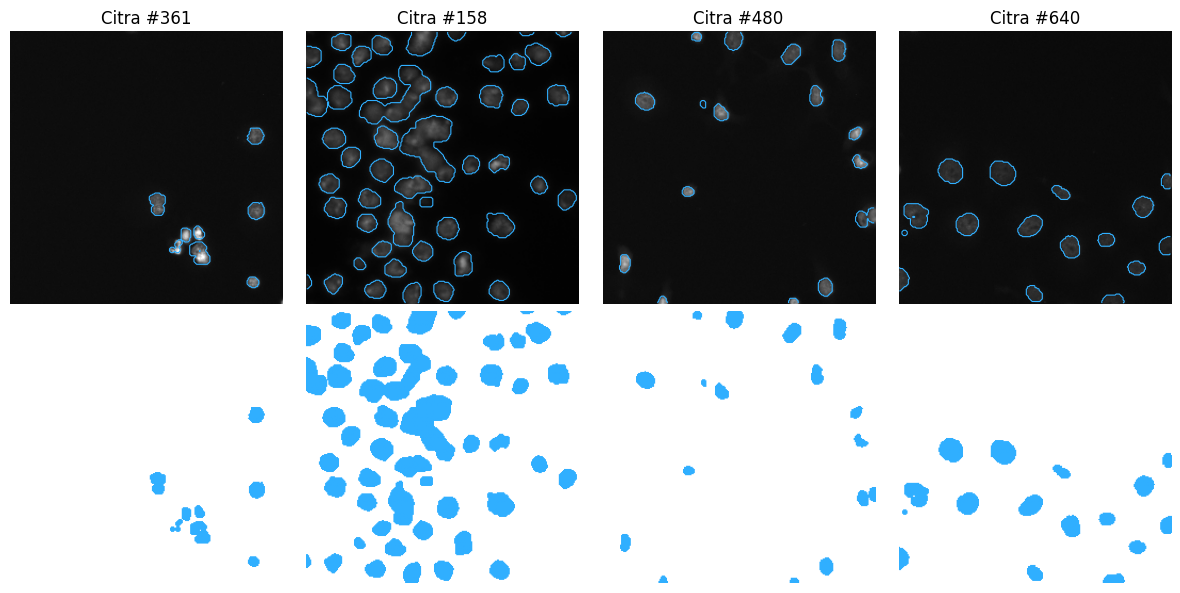

In [4]:
def show_samples(images, masks, n=4):
    idx = np.random.choice(len(images), n, replace=False)
    mask_cmap = ListedColormap(["white", COLORS["blue"]])
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))
    for col, i in enumerate(idx):
        axes[0, col].imshow(images[i])
        axes[0, col].contour(masks[i], levels=[0.5], colors=COLORS["blue"], linewidths=0.8)
        axes[1, col].imshow(masks[i], cmap=mask_cmap)
        axes[0, col].set_title(f"Citra #{i}")
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    plt.show()


is_bright = X.mean(axis=(1, 2, 3)) > 100  # heuristik kasar: brightfield/H&E (terang) vs fluoresens (gelap)
coverage = Y.mean(axis=(1, 2))
print(f"Citra terang: {is_bright.sum()} | gelap: {(~is_bright).sum()}")
print(f"Rasio piksel inti per citra: rata-rata {coverage.mean():.3f}, min {coverage.min():.3f}, maks {coverage.max():.3f}")
show_samples(X, Y)

# Split Data

In [5]:
strata = is_bright.astype(int)
idx_all = np.arange(len(X))
idx_trainval, idx_test = train_test_split(
    idx_all, test_size=CFG["test_size"], stratify=strata, random_state=CFG["seed"]
)
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=CFG["val_size"] / (1 - CFG["test_size"]),
    stratify=strata[idx_trainval], random_state=CFG["seed"],
)

assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test) or set(idx_val) & set(idx_test))
print(f"Train: {len(idx_train)} | Val: {len(idx_val)} | Test: {len(idx_test)}")

Train: 468 | Val: 101 | Test: 101


# Dataset and Data Loader

In [6]:
class NucleiDataset(Dataset):
    def __init__(self, images, masks, augment=False):
        self.images, self.masks, self.augment = images, masks, augment

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        image, mask = self.images[i], self.masks[i]
        if self.augment:
            image, mask = self._augment(image, mask)
        image = torch.from_numpy(np.ascontiguousarray(image)).permute(2, 0, 1).float() / 255
        mask = torch.from_numpy(np.ascontiguousarray(mask)).unsqueeze(0).float()
        return image, mask

    @staticmethod
    def _augment(image, mask):
        k = random.randint(0, 3)
        image, mask = np.rot90(image, k), np.rot90(mask, k)
        if random.random() < 0.5:
            image, mask = image[:, ::-1], mask[:, ::-1]
        return image, mask


def make_loaders(batch_size):
    splits = {"train": idx_train, "val": idx_val, "test": idx_test}
    return {
        name: DataLoader(
            NucleiDataset(X[idx], Y[idx], augment=(name == "train")),
            batch_size=batch_size, shuffle=(name == "train"), num_workers=2, pin_memory=True,
        )
        for name, idx in splits.items()
    }


loaders = make_loaders(CFG["batch_size"])
images, masks = next(iter(loaders["train"]))
print(f"Batch: {tuple(images.shape)} {images.dtype} | {tuple(masks.shape)} | rentang citra [{images.min():.2f}, {images.max():.2f}]")

Batch: (16, 3, 256, 256) torch.float32 | (16, 1, 256, 256) | rentang citra [0.00, 1.00]


# Arsitektur U-Net

In [7]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self, in_ch=3, base=32, depth=4):
        super().__init__()
        ch = [base * 2**i for i in range(depth + 1)]  # contoh base=32, depth=4: [32, 64, 128, 256, 512]
        self.encoders = nn.ModuleList(conv_block(c_in, c_out) for c_in, c_out in zip([in_ch] + ch[:-2], ch[:-1]))
        self.bottleneck = conv_block(ch[-2], ch[-1])
        self.pool = nn.MaxPool2d(2)
        self.upconvs = nn.ModuleList(nn.ConvTranspose2d(hi, lo, 2, stride=2) for hi, lo in zip(ch[:0:-1], ch[-2::-1]))
        self.decoders = nn.ModuleList(conv_block(2 * c, c) for c in ch[-2::-1])
        self.head = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        skips = []
        for encoder in self.encoders:
            x = encoder(x)
            skips.append(x)
            x = self.pool(x)
        x = self.bottleneck(x)
        for up, decoder, skip in zip(self.upconvs, self.decoders, reversed(skips)):
            x = decoder(torch.cat([up(x), skip], dim=1))
        return self.head(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


model = UNet().to(DEVICE)
out = model(images[:2].to(DEVICE))
print(f"Output: {tuple(out.shape)} | Parameter: {count_params(model) / 1e6:.2f} juta")
del model, out

Output: (2, 1, 256, 256) | Parameter: 7.76 juta


# Loss dan Metrik

In [8]:
def dice_loss(logits, target, eps=1.0):
    prob = torch.sigmoid(logits)
    inter = (prob * target).sum((1, 2, 3))
    total = prob.sum((1, 2, 3)) + target.sum((1, 2, 3))
    return 1 - ((2 * inter + eps) / (total + eps)).mean()


def bce_dice_loss(logits, target):
    return F.binary_cross_entropy_with_logits(logits, target) + dice_loss(logits, target)


@torch.no_grad()
def dice_iou(logits, target, eps=1.0):
    pred = (torch.sigmoid(logits) > 0.5).float()
    inter = (pred * target).sum((1, 2, 3))
    total = pred.sum((1, 2, 3)) + target.sum((1, 2, 3))
    return (2 * inter + eps) / (total + eps), (inter + eps) / (total - inter + eps)

# Fungsi Training

In [9]:
def run_epoch(model, loader, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, dices, ious = 0.0, [], []
    with torch.set_grad_enabled(training):
        for image, mask in loader:
            image, mask = image.to(DEVICE, non_blocking=True), mask.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE, enabled=DEVICE == "cuda"):
                logits = model(image)
            loss = bce_dice_loss(logits.float(), mask)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            dice, iou = dice_iou(logits.float(), mask)
            loss_sum += loss.item() * image.size(0)
            dices.append(dice)
            ious.append(iou)
    n = len(loader.dataset)
    return {"loss": loss_sum / n, "dice": torch.cat(dices).mean().item(), "iou": torch.cat(ious).mean().item()}


def fit(model, loaders, epochs, lr, desc="Training"):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    history, best_dice, best_state = [], -1.0, None
    bar = tqdm(range(1, epochs + 1), desc=desc)
    for epoch in bar:
        train = run_epoch(model, loaders["train"], optimizer, scaler)
        val = run_epoch(model, loaders["val"])
        scheduler.step()
        history.append({"epoch": epoch, **{f"train_{k}": v for k, v in train.items()}, **{f"val_{k}": v for k, v in val.items()}})
        if val["dice"] > best_dice:
            best_dice, best_state = val["dice"], copy.deepcopy(model.state_dict())
        bar.set_postfix(val_dice=f"{val['dice']:.3f}", best=f"{best_dice:.3f}")
    model.load_state_dict(best_state)
    return pd.DataFrame(history)

# Uji Parameter U-net

In [10]:
GRID = [
    {"base": 16, "depth": 4},
    {"base": 32, "depth": 3},
    {"base": 32, "depth": 4},
    {"base": 64, "depth": 4},
]


def run_experiment(params):
    seed_everything(CFG["seed"])
    model = UNet(**params).to(DEVICE)
    start = time.perf_counter()
    history = fit(model, loaders, CFG["exp_epochs"], CFG["lr"], desc=f"base={params['base']} depth={params['depth']}")
    best = history.loc[history["val_dice"].idxmax()]
    row = {
        **params, "params_M": count_params(model) / 1e6, "val_dice": best["val_dice"],
        "val_iou": best["val_iou"], "best_epoch": int(best["epoch"]), "time_s": time.perf_counter() - start,
    }
    del model
    torch.cuda.empty_cache()
    return row, history


outputs = [run_experiment(p) for p in GRID]
results = pd.DataFrame([row for row, _ in outputs])
histories = [hist for _, hist in outputs]
results.round(4).sort_values("val_dice", ascending=False)

base=16 depth=4:   0%|          | 0/15 [00:00<?, ?it/s]

base=32 depth=3:   0%|          | 0/15 [00:00<?, ?it/s]

base=32 depth=4:   0%|          | 0/15 [00:00<?, ?it/s]

base=64 depth=4:   0%|          | 0/15 [00:00<?, ?it/s]

,base,depth,params_M,val_dice,val_iou,best_epoch,time_s
0,16,4,1.9426,0.8957,0.8214,11,47.3781
3,64,4,31.0376,0.8939,0.8170,15,192.9468
2,32,4,7.7630,0.8900,0.8176,14,80.2385
1,32,3,1.9270,0.8898,0.8169,13,69.0918


# Visualisasi Percobaan

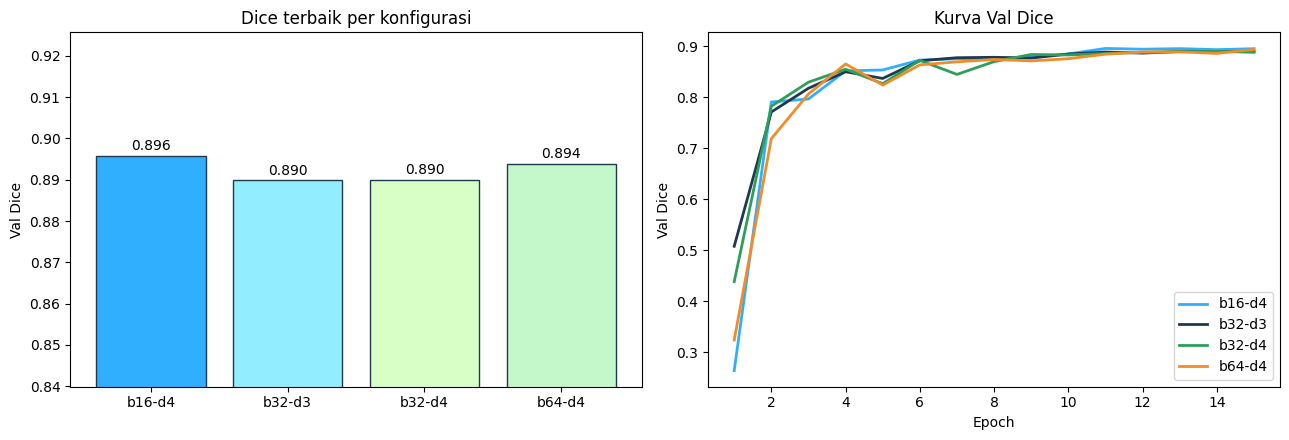

In [11]:
bar_colors = [COLORS["blue"], COLORS["cyan"], COLORS["lime"], COLORS["mint"]]
line_colors = [COLORS["blue"], COLORS["navy"], COLORS["green"], COLORS["orange"]]
labels = [f"b{r.base}-d{r.depth}" for r in results.itertuples()]

fig, (ax_bar, ax_curve) = plt.subplots(1, 2, figsize=(13, 4.5))
bars = ax_bar.bar(labels, results["val_dice"], color=bar_colors, edgecolor=COLORS["navy"])
ax_bar.bar_label(bars, fmt="%.3f", padding=2)
ax_bar.set(ylim=(results["val_dice"].min() - 0.05, results["val_dice"].max() + 0.03), ylabel="Val Dice", title="Dice terbaik per konfigurasi")

for hist, label, color in zip(histories, labels, line_colors):
    ax_curve.plot(hist["epoch"], hist["val_dice"], label=label, color=color, linewidth=2)
ax_curve.set(xlabel="Epoch", ylabel="Val Dice", title="Kurva Val Dice")
ax_curve.legend()
plt.tight_layout()
plt.show()

# Training Final

In [12]:
best_params = results.loc[results["val_dice"].idxmax(), ["base", "depth"]].astype(int).to_dict()
print(f"Konfigurasi terpilih: {best_params}")

seed_everything(CFG["seed"])
final_model = UNet(**best_params).to(DEVICE)
final_history = fit(final_model, loaders, CFG["final_epochs"], CFG["lr"], desc="Training final")

Konfigurasi terpilih: {'base': 16, 'depth': 4}


Training final:   0%|          | 0/40 [00:00<?, ?it/s]

# Kurva Training Final

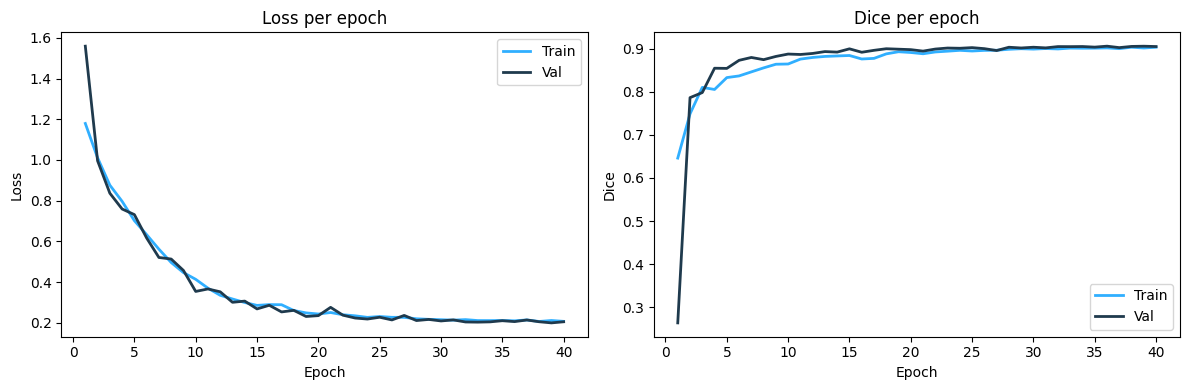

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "dice"]):
    ax.plot(final_history["epoch"], final_history[f"train_{metric}"], color=COLORS["blue"], linewidth=2, label="Train")
    ax.plot(final_history["epoch"], final_history[f"val_{metric}"], color=COLORS["navy"], linewidth=2, label="Val")
    ax.set(xlabel="Epoch", ylabel=metric.capitalize(), title=f"{metric.capitalize()} per epoch")
    ax.legend()
plt.tight_layout()
plt.show()

# Evaluasi Tes dan Prediksi

Test | Dice: 0.8916 | IoU: 0.8165 | Loss: 0.2314


/tmp/ipykernel_23/3211768681.py:18: UserWarning: The following kwargs were not used by contour: 'linewidth'
  axes[row, i].contour(data[i, 0].cpu().numpy(), levels=[0.5], colors=color, linewidth=1)


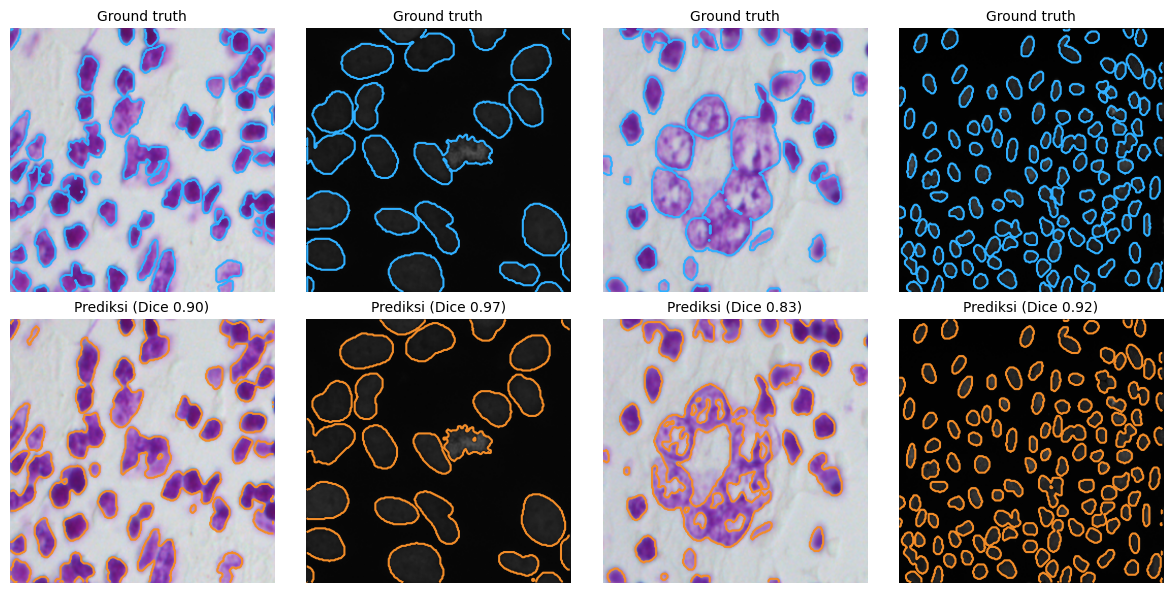

In [14]:
test_scores = run_epoch(final_model, loaders["test"])
print(f"Test | Dice: {test_scores['dice']:.4f} | IoU: {test_scores['iou']:.4f} | Loss: {test_scores['loss']:.4f}")


@torch.no_grad()
def show_predictions(model, loader, n=4):
    model.eval()
    image, mask = next(iter(loader))
    image, mask = image[:n].to(DEVICE), mask[:n].to(DEVICE)
    logits = model(image)
    pred = (torch.sigmoid(logits) > 0.5).float()
    dice, _ = dice_iou(logits, mask)
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))
    for i in range(n):
        img = image[i].permute(1, 2, 0).cpu().numpy()
        for row, (data, color, name) in enumerate([(mask, COLORS["blue"], "Ground truth"), (pred, COLORS["orange"], f"Prediksi (Dice {dice[i]:.2f})")]):
            axes[row, i].imshow(img)
            axes[row, i].contour(data[i, 0].cpu().numpy(), levels=[0.5], colors=color, linewidth=1)
            axes[row, i].set_title(name, fontsize=10)
            axes[row, i].axis("off")
    plt.tight_layout()
    plt.show()


show_predictions(final_model, loaders["test"])